In [214]:
from pathlib import Path

import pandas as pd
import torch
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PROJECT_ROOT = Path.cwd().parent  # If notebook is in notebooks/
DATA_DIR = PROJECT_ROOT / "data"
df = pd.read_csv(DATA_DIR / "final_data.csv")
df = df[(df["NV"] == 1) | (df["MEL"] == 1)]

import torch

model = torch.load("../models/mel-vs-nv-full.pth", map_location=device, weights_only=False)
model.eval()
model = model.to(device)

In [215]:
x = torch.randn(1, 3, 224, 224, device=device)

output = model(x)

# print(output.shape)
print(output)

(tensor([0.9885], grad_fn=<MeanBackward1>), tensor([True]))


In [216]:
target_layers = [model.get_submodule(f"folds.{fold_name}.encoder.layer4.1.conv2") for fold_name, _ in model.folds.named_children()]

print(target_layers)

[Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False), Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False), Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)]


In [217]:
# create the Grad CAM Wrapper
from torch import nn


class GradCAMWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(x)[0].reshape(-1, 1)


cam_model = GradCAMWrapper(model)

In [218]:
# from pytorch_grad_cam import GradCAM
# from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

# cam = GradCAM(
#     model=cam_model,
#     target_layers=[target_layer]
# )

# targets = [ClassifierOutputTarget(0)]

In [219]:
from pathlib import Path

import numpy as np
import torch
from PIL import Image

image_path = Path("../data") / df.iloc[3]["path"]

image = Image.open(image_path).convert("RGB")

In [220]:
print(type(image))
print(image.size)

<class 'PIL.Image.Image'>
(600, 450)


In [221]:
from torchvision import transforms

input_tensor = transforms.PILToTensor()(image).unsqueeze(0)
input_tensor = input_tensor.to(device=device, dtype=torch.float32).requires_grad_(True)
print(input_tensor.shape)

torch.Size([1, 3, 450, 600])


In [222]:
cam = GradCAM(model=cam_model, target_layers=target_layers)

In [223]:
called_layers = []


def record_layer(module, inputs, output):
    called_layers.append(module)


handles = []

for name, module in model.named_modules():
    if name.startswith("folds.0.encoder.layer4"):
        handles.append(module.register_forward_hook(lambda m, i, o, name=name: called_layers.append(name)))

with torch.no_grad():
    model(input_tensor)

for handle in handles:
    handle.remove()

print(called_layers)

['folds.0.encoder.layer4.0.conv1', 'folds.0.encoder.layer4.0.bn1', 'folds.0.encoder.layer4.0.relu', 'folds.0.encoder.layer4.0.conv2', 'folds.0.encoder.layer4.0.bn2', 'folds.0.encoder.layer4.0.downsample.0', 'folds.0.encoder.layer4.0.downsample.1', 'folds.0.encoder.layer4.0.relu', 'folds.0.encoder.layer4.1.conv1', 'folds.0.encoder.layer4.1.bn1', 'folds.0.encoder.layer4.1.relu', 'folds.0.encoder.layer4.1.conv2', 'folds.0.encoder.layer4.1.bn2', 'folds.0.encoder.layer4.1.relu']


In [224]:
# Grad-CAM accepts ClassifierOutputTarget as a callable.
grayscale_cam = cam(input_tensor=input_tensor, targets=[ClassifierOutputTarget(0)])  # pyright: ignore[reportArgumentType]

grayscale_cam = grayscale_cam[0]

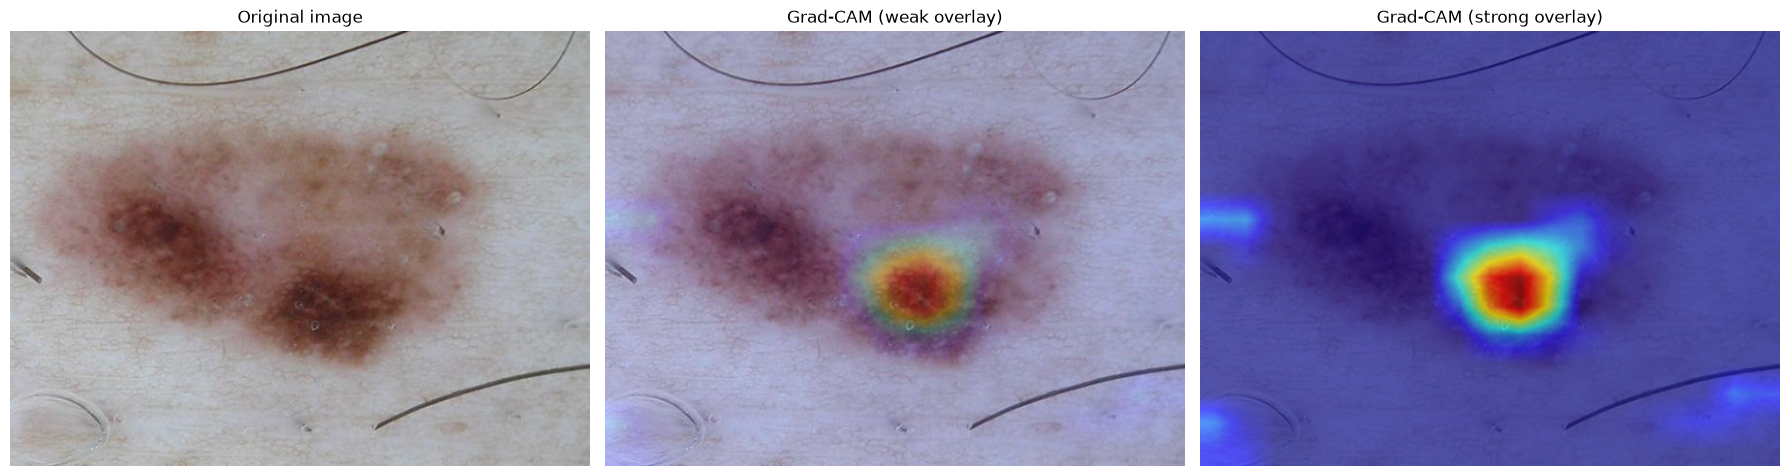

In [225]:
import matplotlib.pyplot as plt
import numpy as np

# Original image as RGB, scaled to [0, 1]
rgb_img = np.array(image).astype(np.float32) / 255.0

# Different heatmap transparency levels
cam_weak = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True, image_weight=0.8)

cam_strong = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True, image_weight=0.4)

# Side-by-side visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(rgb_img)
axes[0].set_title("Original image")

axes[1].imshow(cam_weak)
axes[1].set_title("Grad-CAM (weak overlay)")

axes[2].imshow(cam_strong)
axes[2].set_title("Grad-CAM (strong overlay)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()